# Full run, step by step

This notebook runs the stress engine on one input set, exactly as `uv run stress run` does, and then shows what each step R1–R11 produced. Every table is read back from the sealed run folder `runs/<run_id>/`, so what you see is what the run sealed. Nothing is edited. The few checks recompute an identity from the run's own tables.

| Step | What it does | Tables shown |
|---|---|---|
| R1 | Open the run | config, versions |
| R2 | Load inputs | the seven datasets in `data/` |
| R3 | Validate and route | `rejections`, starting-point reconciliation |
| R4 | Scenarios and Z-score | `indices`, `driver_contributions`, `drivers` |
| R5 | Contractual cash flows | `cf_schedule` |
| R6 | Parameters | `pit_matrices`, `pd_curves`, `lgd_of_year`, `parameters` |
| R7 | Project the year | `slices`, `stage_flows`, `grade_flows` |
| R8 | Year-end provisions | `provisions`, `ecl_buckets` |
| R9 | Stock to flow | `charges` |
| R10 | Reports | `reports/*.csv`, `summary.md` |
| R11 | Seal the run | `manifest.json` |

One facility is followed from its cash flows (R5) to its charge (R9). Use the project kernel (`.venv`); setup is in [README.md](README.md).

## Settings

A new run takes about 30 seconds and writes a new folder under `runs/`. To look at a run that already exists, set `RUN_ID` to its folder name or to `"latest"`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter
from scipy.stats import norm

import nbtools as nb

INPUTS = "inputs/514ed0e86e3dc760"  # the current input set; the table below lists them all
SCENARIOS = ("baseline", "adverse")
VARIANT = "core"  # core, annuity, linear or utilisation
RUN_ID = None  # None starts a new run; "latest" or a run ID opens a sealed one
FACILITY = None  # the facility followed from R5 to R9; None picks one with an undrawn line

nb.setup()
nb.input_sets()

,inputs,status,parameter_set,generator,approval
0,inputs/32415eb9d5bbcd74,SYNTHETIC,SYN-PS-0.1-proposed,0.1.0,PENDING_OWNER_APPROVAL
1,inputs/514ed0e86e3dc760,SYNTHETIC,SYN-PS-0.1-proposed,0.1.0,PENDING_OWNER_APPROVAL


## Run R1–R11

The output is the engine's step log: a line when each step starts and when it ends, with its duration. R7–R9 repeat for each scenario and projected year. R8 also values the opening book once, as a diagnostic next to the frozen opening allowances. The full log, with times, is `run.log` in the run folder.

In [2]:
if RUN_ID is None:
    run = nb.run_engine(INPUTS, SCENARIOS, VARIANT)
else:
    run = nb.open_run(RUN_ID, variant=VARIANT)

ps = run.data("parameter_set")
grades = run.grades()
start_year = int(ps["horizon"]["snapshot_year"])
years = [int(y) for y in ps["horizon"]["projection_years"]]
first = years[0]
scenarios = run.scenarios
stressed = scenarios[-1]  # the scenario shown where only one fits
names = run.portfolio_names()
run

stress.R1  run 20261017T2302Z-core-b559d9dd opened in C:/projects/stresstest_repo/runs/20261017T2302Z-core-b559d9dd


stress.R1  input set 514ed0e86e3dc760; scenarios baseline, adverse; variant core; mode synthetic; status label SYNTHETIC


stress.R1  code 0.1.0+03f04577c21e+dirty.5743ea01; spec version 1.3


stress.R2  start: load inputs


stress.R2  all 7 files match their manifest hashes (input set 514ed0e86e3dc760)


...

stress.R10 wrote 19 reports to results/reports: driver_contributions.csv, ead_profile.csv, ecl_by_bucket.csv, grade_migration.csv, impairment.csv, impairment_by_stage.csv, lgd_by_z.csv, pd_curves.csv, pit_matrices.csv, portfolio_pd.csv, property_indices.csv, s3_cohorts.csv, stage_migration.csv, starting_point_reconciliation.csv, static_books.csv, stress_report.xlsx, summary.md, ttc_matrices.csv, z_scores.csv


stress.R10 done in 5.2 s


stress.R11 sealing the run as SYNTHETIC after 26.4 s


stress.R11 sealed: 34 outputs, digest d945f6a1ac88ef0e


Run('20261017T2302Z-core-b559d9dd', status=SYNTHETIC, folder='C:/projects/stresstest_repo/runs/20261017T2302Z-core-b559d9dd')

## R1 · Open the run

R1 fixes the input set by its content hash and records the code, spec and parameter-set versions. Every preparation run is labelled SYNTHETIC, and regulatory mode blocks in v1. The run ID ends in a hash of the config, the input set, the code version and the spec version.

In [3]:
display(run.overview().to_frame())
print(run.config_yaml())

,run
run_id,20261017T2302Z-core-b559d9dd
status,SYNTHETIC
label,SYNTHETIC
mode,synthetic
variant,core
scenarios,"baseline, adverse"
input set,514ed0e86e3dc7604771bcd38d709a99976feca653a4bf...
input generator,"{'name': 'foundation.synth', 'seed': 20261231,..."
parameter set,SYN-PS-0.1-proposed v0.1 (PROPOSED)
code version,0.1.0+03f04577c21e+dirty.5743ea01


input_set_hash: 514ed0e86e3dc7604771bcd38d709a99976feca653a4bfd578f91ab0880a143c
inputs: inputs/514ed0e86e3dc760
mode: synthetic
scenarios:
- baseline
- adverse
variant: core



## R2 · Load inputs

R2 reads the seven datasets, checks every file against its hash in the input-set manifest, and records row counts. The run keeps a copy in `data/`, which is what is read here. No later step reads a file.

In [4]:
loaded = pd.Series(run.manifest["load_controls"], name="rows loaded by R2")
in_data = pd.Series({name: len(run.data(name)) for name in loaded.index if name != "scenario_values"},
                    name="rows in data/")
pd.concat([loaded, in_data], axis=1)

,rows loaded by R2,rows in data/
commitments,931,931.0
facilities,10000,10000.0
obligors,8320,8320.0
opening_provisions,10000,10000.0
scenario_values,180,NaN
ttc_pd_matrix,847,847.0


The book at the starting point, by portfolio. Amounts in EUR millions; rates, maturities and LGDs are simple means.

In [5]:
book = run.book()
undrawn = run.data("commitments").groupby("facility_id")["nominal_undrawn"].sum()
book["undrawn"] = book["facility_id"].map(undrawn).fillna(0.0)

by_stage = book.pivot_table(index="portfolio", columns="ifrs_stage", values="gca", aggfunc="sum",
                            fill_value=0.0).rename(columns=lambda s: f"S{s} GCA")
portfolios = book.groupby("portfolio").agg(
    facilities=("facility_id", "size"), gca=("gca", "sum"), undrawn=("undrawn", "sum"),
    mean_rate=("interest_rate", "mean"), mean_maturity=("residual_maturity", "mean"),
    mean_ttc_lgd=("ttc_lgd", "mean"),
).join(by_stage)
portfolios.insert(0, "name", portfolios.index.map(names))
print(f"{len(book):,} facilities; GCA EUR {book['gca'].sum() / nb.MILLION:,.1f}m; "
      f"undrawn EUR {book['undrawn'].sum() / nb.MILLION:,.1f}m")
means = {"mean_rate": "{:.2%}", "mean_maturity": "{:.1f}", "mean_ttc_lgd": "{:.1%}"}
nb.millions(portfolios, ["gca", "undrawn", *by_stage.columns]).format(means, subset=list(means))

10,000 facilities; GCA EUR 11,000.0m; undrawn EUR 2,000.0m


,name,facilities,gca,undrawn,mean_rate,mean_maturity,mean_ttc_lgd,S1 GCA,S2 GCA,S3 GCA
portfolio,,,,,,,,,,
P01,mortgage (households),4000,"1,200.0",0.0,3.00%,20.0,14.9%,"1,056.0",120.0,24.0
P02,consumer loan (households),3000,60.0,0.0,8.99%,3.9,74.9%,48.6,9.0,2.4
P03,"revolver, term loan (non financial corporations)",1500,"1,500.0",600.0,5.00%,4.5,40.5%,"1,155.0",270.0,75.0
P04,term loan (non financial corporations),500,"2,000.0",0.0,4.49%,6.4,34.6%,"1,480.0",400.0,120.0
P05,"revolver, term loan (non financial corporations)",800,"4,000.0","1,400.0",4.02%,5.6,34.6%,"3,400.0",480.0,120.0
P06,"debt security (credit institutions, general governments)",200,"2,240.0",0.0,2.38%,7.8,31.6%,"2,128.0",89.6,22.4


The parameter set per segment, and the master scale. These values are proposed, not owner-approved (assumption A2): ρ is the asset correlation in the Z shift, `sicr_k` the SICR multiple, `lgd_w` the LGD sensitivity to Z, and `cpr_ttc` and `cpr_v` the prepayment rate and its sensitivity.

In [6]:
print(f"{ps['parameter_set_id']} version {ps['version']}, status {ps['status']}")
segments = pd.DataFrame({s: {k: v for k, v in p.items() if k not in ("z_drivers", "portfolio")}
                         for s, p in ps["segments"].items()}).T
display(segments)
pd.Series(ps["master_scale"]["ttc_pd"], index=grades, name="TTC one-year PD").to_frame().T.style.format("{:.2%}")

SYN-PS-0.1-proposed version 0.1, status PROPOSED


,rho,sicr_k,lgd_w,cpr_ttc,cpr_v,ccf
P01,0.15,2.5,0.20,0.06,0.25,NaN
P02,0.06,2.0,0.10,0.10,0.20,NaN
P03,0.12,2.5,0.15,0.05,0.15,0.5
P04,0.15,2.5,0.25,0.03,0.15,NaN
P05,0.12,2.5,0.15,0.05,0.15,0.5
P06_GG,0.20,3.0,0.10,0.00,0.00,NaN
P06_CI,0.20,3.0,0.10,0.00,0.00,NaN


,G1,G2,G3,G4,G5,G6,G7,G8,G9,G10
TTC one-year PD,0.02%,0.05%,0.12%,0.30%,0.70%,1.60%,3.00%,4.80%,9.00%,18.00%


### The facility followed through R5–R9

By default, the first facility with an undrawn commitment and three to six years to maturity. Its segment and country set which matrices and curves are shown below.

In [7]:
if FACILITY is None:
    committed = book[book["undrawn"] > 0].sort_values("facility_id")
    in_range = committed[committed["residual_maturity"].between(3, 6)]
    FACILITY = (in_range if len(in_range) else committed).iloc[0]["facility_id"]
facility = book.set_index("facility_id").loc[FACILITY]
segment, country = facility["segment"], facility["country"]
facility[["portfolio", "segment", "country", "product", "ifrs_stage", "current_grade",
          "origination_grade", "gca", "undrawn", "interest_rate", "rate_type", "residual_maturity",
          "repayment_profile", "ttc_lgd"]].to_frame(FACILITY)

,F07007
portfolio,P03
segment,P03
country,IT
product,revolver
ifrs_stage,1
current_grade,G5
origination_grade,G4
gca,845025.91256
undrawn,1318836.810253
interest_rate,0.045574


## R3 · Validate and route

R3 checks the schema, referential integrity, the EUR-only and AC-only scope, every TTC matrix, and whether each facility's grade explains its reported stage. A rejected record goes to `rejections.parquet` with a reason code and never reaches a total.

In [8]:
rejections = run.table("rejections")
print(f"{len(rejections):,} rejected records; manifest: {run.manifest['rejections']}")
if len(rejections):
    display(rejections.groupby(["record_type", "reason_code"]).size().rename("records").to_frame())

0 rejected records; manifest: {'facilities': 0, 'records': 0}


The starting point reconciled, per portfolio and stage. `engine_2026_<scenario>_on` and `_off` are the engine's own end-2026 valuation, a diagnostic next to the frozen O4 allowance (assumption A16). Charges always start from the frozen allowance. EUR millions.

In [9]:
start = run.report("starting_point_reconciliation")
amounts = ["loaded_gca", "rejected_gca", "accepted_gca", "accepted_undrawn", "converted_commitments",
           "opening_allowance_on", "opening_provision_off",
           *[c for c in start.columns if c.startswith("engine_2026_")]]
view = start.set_index(["portfolio", "stage"])[["loaded_count", "accepted_count", *amounts]]
nb.millions(view, amounts)

## R4 · Scenarios and Z-score

R4 compounds the property price changes into indices. It then standardises each macro driver and combines the results into one Z per segment, country, year and scenario: Z = Σ β · (x − μ) / σ. A positive Z means a better economy than average. The same Z drives the PD matrix, LGD and prepayment. After the last scenario year, adverse reverts linearly to the baseline Z, and both then stay flat until the last bucket year.

In [10]:
indices = run.table("indices")
print(f"Property price indices, {country}")
indices[indices["country"] == country].pivot_table(index="year", columns=["variable", "scenario"],
                                                   values="index")

Property price indices, IT


variable cre_price_index           residential_price_index          
scenario         adverse  baseline                 adverse  baseline
year                                                                
2027               85.00  102.0000                  88.000  102.0000
2028               74.80  104.5500                  79.200  104.5500
2029               71.06  107.6865                  76.824  107.6865

In [11]:
contrib = run.table("driver_contributions")
z = run.table("drivers")
mine = contrib[(contrib["segment"] == segment) & (contrib["country"] == country)]
print(f"Driver contributions to Z, {segment} {country}")
display(mine.drop(columns=["segment", "country"]).set_index(["scenario", "year", "driver"]))

key = ["segment", "country", "scenario", "year"]
total = contrib.groupby(key)["contribution"].sum()
gap = (z.set_index(key)["z"].reindex(total.index) - total).abs().max()
spread = z.groupby(["segment", "scenario", "year"])["z"].nunique().max()
print(f"largest |Z - sum of contributions|: {gap:.1e}")
print(f"distinct Z values across countries for one segment, scenario and year: {spread} (A5)")

Driver contributions to Z, P03 IT


value   mean     sd  beta  contribution
scenario year driver                                                 
adverse  2027 gdp_growth     -0.030  0.015  0.030   0.6     -0.900000
              reference_rate  0.040  0.025  0.015  -0.2     -0.200000
              unemployment    0.075  0.065  0.020  -0.2     -0.100000
         2028 gdp_growth     -0.020  0.015  0.030   0.6     -0.700000
              reference_rate  0.045  0.025  0.015  -0.2     -0.266667
              unemployment    0.090  0.065  0.020  -0.2     -0.250000
         2029 gdp_growth      0.005  0.015  0.030   0.6     -0.200000
              reference_rate  0.035  0.025  0.015  -0.2     -0.133333
              unemployment    0.092  0.065  0.020  -0.2     -0.270000
baseline 2027 gdp_growth      0.015  0.015  0.030   0.6      0.000000
              reference_rate  0.025  0.025  0.015  -0.2     -0.000000
              unemployment    0.060  0.065  0.020  -0.2      0.050000
         2028 gdp_growth      0.017  0.015  0.030   0.6      0.040000
              reference_rate  0.023  0.025  0.015  -0.2      0.026667
              unemployment    0.058  0.065  0.020  -0.2      0.070000
         2029 gdp_growth      0.018  0.015  0.030   0.6      0.060000
              reference_rate  0.022  0.025  0.015  -0.2      0.040000
              unemployment    0.057  0.065  0.020  -0.2      0.080000

largest |Z - sum of contributions|: 0.0e+00
distinct Z values across countries for one segment, scenario and year: 1 (A5)


In [12]:
last_moving = int(z.loc[z["z_source"] != "flat", "year"].max())
path = z[(z["segment"] == segment) & (z["country"] == country) & (z["year"] <= last_moving + 1)]
print(f"Z of {segment} {country}: scenario path, reversion, then flat until {z['year'].max()}")
path.pivot(index="year", columns="scenario", values=["z", "z_source", "adverse_weight"])

Z of P03 IT: scenario path, reversion, then flat until 2060


z                 z_source                adverse_weight         
scenario   adverse  baseline        adverse       baseline        adverse baseline
year                                                                              
2027          -1.2      0.05  scenario_path  scenario_path            1.0      1.0
2028     -1.216667  0.136667  scenario_path  scenario_path            1.0      1.0
2029     -0.603333      0.18  scenario_path  scenario_path            1.0      1.0
2030     -0.472778      0.18      reversion           flat       0.833333      1.0
2031     -0.342222      0.18      reversion           flat       0.666667      1.0
2032     -0.211667      0.18      reversion           flat            0.5      1.0
2033     -0.081111      0.18      reversion           flat       0.333333      1.0
2034      0.049444      0.18      reversion           flat       0.166667      1.0
2035          0.18      0.18           flat           flat            0.0      1.0

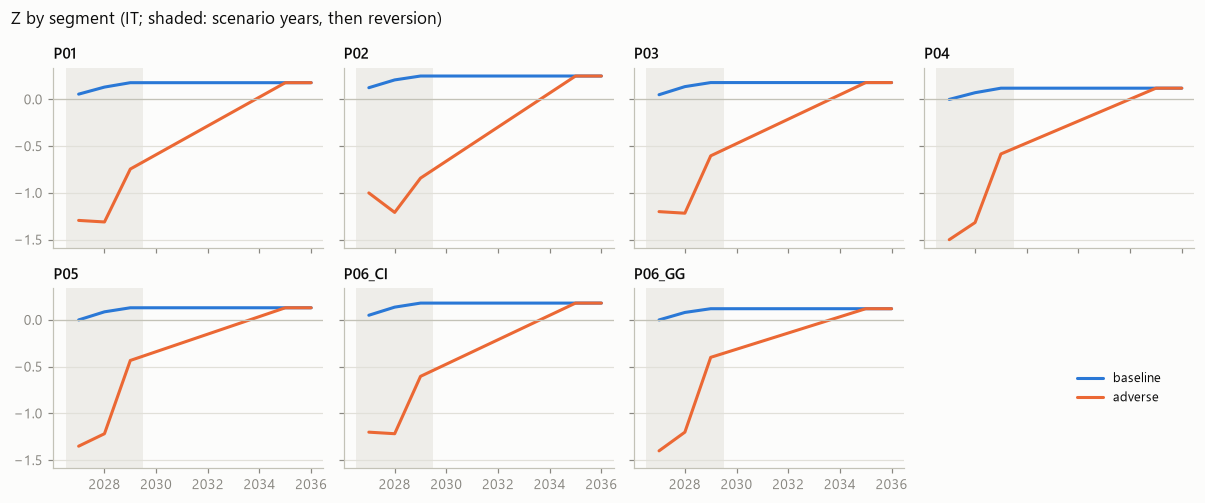

In [13]:
shown = z[(z["country"] == country) & (z["year"] <= last_moving + 2)]
segment_ids = sorted(z["segment"].unique())
fig, axes = plt.subplots(2, (len(segment_ids) + 2) // 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, seg in zip(axes.flat, segment_ids):
    for s in scenarios:
        line = shown[(shown["segment"] == seg) & (shown["scenario"] == s)]
        ax.plot(line["year"], line["z"], color=nb.SCENARIO_COLOURS[s], label=s)
    ax.axhline(0, color=nb.AXIS, linewidth=0.8)
    ax.axvspan(first - 0.5, years[-1] + 0.5, color=nb.GRID, alpha=0.5, linewidth=0)
    ax.set_title(seg, loc="left")
for ax in list(axes.flat)[len(segment_ids):]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower right", bbox_to_anchor=(0.97, 0.18))
fig.suptitle(f"Z by segment ({country}; shaded: scenario years, then reversion)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

## R5 · Contractual cash flows

R5 is the only step that creates cash flows. From balance, rate and maturity it builds a yearly contractual schedule to maturity: opening balance, interest, principal, closing balance and the discount factor from the same rate. The schedule is the same in every scenario. At each valuation year-end it restarts from the static stock balance (A15), so each facility has one schedule per valuation year. Under `core` every facility is bullet (A11).

In [14]:
schedule = run.table("cf_schedule")
print(f"{len(schedule):,} schedule rows for {schedule['facility_id'].nunique():,} facilities")
display(schedule.groupby(["valuation_year", "profile"]).agg(
    facilities=("facility_id", "nunique"), periods=("period", "size")))
ends = schedule.sort_values("period").groupby(["facility_id", "valuation_year"]).tail(1)
print("largest closing balance at maturity (every schedule ends at zero): "
      f"{ends['closing_balance'].abs().max():.2e}")

383,819 schedule rows for 9,669 facilities


,,facilities,periods
valuation_year,profile,,
2026,bullet,9669,109548
2027,bullet,9669,100038
2028,bullet,9669,90951
2029,bullet,9669,83282


largest closing balance at maturity (every schedule ends at zero): 0.00e+00


In [15]:
print(f"Schedule of {FACILITY} from end-{start_year}")
schedule[(schedule["facility_id"] == FACILITY) & (schedule["valuation_year"] == start_year)]

Schedule of F07007 from end-2026


,facility_id,valuation_year,period,period_end,bucket_year,fraction,t,opening_balance,interest,principal,closing_balance,discount_factor,profile,generation,remaining_maturity
332988,F07007,2026,1,2027-12-31,2027,1.000000,1.000000,845025.91256,38511.360845,0.00000,845025.91256,0.956412,bullet,0,5.416667
332989,F07007,2026,2,2028-12-31,2028,1.000000,2.000000,845025.91256,38511.360845,0.00000,845025.91256,0.914724,bullet,0,5.416667
332990,F07007,2026,3,2029-12-31,2029,1.000000,3.000000,845025.91256,38511.360845,0.00000,845025.91256,0.874854,bullet,0,5.416667
332991,F07007,2026,4,2030-12-31,2030,1.000000,4.000000,845025.91256,38511.360845,0.00000,845025.91256,0.836721,bullet,0,5.416667
332992,F07007,2026,5,2031-12-31,2031,1.000000,5.000000,845025.91256,38511.360845,0.00000,845025.91256,0.800250,bullet,0,5.416667
332993,F07007,2026,6,2032-05-31,2032,0.416667,5.416667,845025.91256,15838.088267,845025.91256,0.00000,0.785527,bullet,0,5.416667


## R6 · Parameters

R6 builds every scenario-dependent value for each facility, scenario and default bucket.

- **PD:** each segment's TTC matrix is shifted by the year's Z into a point-in-time (PiT) matrix M(y). The cumulative PD F[k] is the default column of M(y+1) × … × M(y+k).
- **LGD:** Φ(Φ⁻¹(LGD_TTC) − w · Z).
- **EAD:** the contractual balance from R5 times the share not yet prepaid, plus undrawn × CCF.

### PiT matrices

In [16]:
ttc = run.data("ttc_pd_matrix")
pit = run.table("pit_matrices")


def matrix(df):
    m = df.pivot_table(index="from_grade", columns="to_grade", values="probability")
    return m.reindex(index=nb.grade_order(m.index, grades), columns=nb.grade_order(m.columns, grades))


ttc_m = matrix(ttc[ttc["segment"] == segment])
pit_m = {s: matrix(pit[(pit["segment"] == segment) & (pit["country"] == country)
                       & (pit["scenario"] == s) & (pit["year"] == first)]) for s in scenarios}
row_sums = pit.groupby(["segment", "country", "scenario", "year", "from_grade"])["probability"].sum()
print(f"{len(row_sums):,} PiT rows; largest |row sum - 1|: {(row_sums - 1).abs().max():.1e}")
print(f"One-year PD by grade, {segment} {country}: TTC and PiT {first}")
pd.DataFrame({"TTC": ttc_m["D"], **{f"PiT {s}": m["D"] for s, m in pit_m.items()}}).drop(
    index="D").style.format("{:.3%}")

9,240 PiT rows; largest |row sum - 1|: 2.2e-16
One-year PD by grade, P03 IT: TTC and PiT 2027


,TTC,PiT baseline,PiT adverse
from_grade,,,
G1,0.020%,0.007%,0.043%
G2,0.050%,0.021%,0.109%
G3,0.120%,0.057%,0.261%
G4,0.300%,0.160%,0.646%
G5,0.700%,0.417%,1.477%
G6,1.600%,1.060%,3.268%
G7,3.000%,2.152%,5.917%
G8,4.800%,3.649%,9.155%
G9,9.000%,7.385%,16.204%


How the stressed year moves probability mass, as PiT minus TTC in percentage points. Red cells gain probability and blue cells lose it, so under stress the diagonal loses mass to downgrades and to D.

In [17]:
shift = pit_m[stressed] - ttc_m
limit = shift.abs().max().max()
print(f"PiT {stressed} {first} minus TTC, {segment} {country}")
shift.style.format("{:+.2%}").background_gradient(cmap=nb.DIVERGING, vmin=-limit, vmax=limit, axis=None)

PiT adverse 2027 minus TTC, P03 IT


to_grade,G1,G2,G3,G4,G5,G6,G7,G8,G9,G10,D
from_grade,,,,,,,,,,,
G1,-7.75%,+4.84%,+1.91%,+0.66%,+0.21%,+0.07%,+0.02%,+0.01%,+0.00%,+0.00%,+0.02%
G2,-5.44%,-2.33%,+4.84%,+1.91%,+0.66%,+0.21%,+0.07%,+0.02%,+0.01%,+0.00%,+0.06%
G3,-1.48%,-3.96%,-2.37%,+4.82%,+1.90%,+0.65%,+0.21%,+0.06%,+0.02%,+0.01%,+0.14%
G4,-0.45%,-1.32%,-3.66%,-2.47%,+4.77%,+1.87%,+0.64%,+0.20%,+0.06%,+0.02%,+0.35%
G5,-0.14%,-0.42%,-1.28%,-3.57%,-2.69%,+4.67%,+1.81%,+0.61%,+0.19%,+0.06%,+0.78%
G6,-0.04%,-0.13%,-0.42%,-1.26%,-3.52%,-3.19%,+4.46%,+1.70%,+0.56%,+0.17%,+1.67%
G7,-0.01%,-0.04%,-0.13%,-0.41%,-1.24%,-3.48%,-3.92%,+4.22%,+1.58%,+0.52%,+2.92%
G8,-0.00%,-0.01%,-0.04%,-0.13%,-0.40%,-1.22%,-3.42%,-4.82%,+4.14%,+1.55%,+4.35%
G9,-0.00%,-0.00%,-0.01%,-0.04%,-0.12%,-0.38%,-1.17%,-3.30%,-6.69%,+4.51%,+7.20%


### PD curves

Cumulative PD from the starting point for a low grade, the followed facility's grade and a high grade. In the PD-03 identities, the marginal PD is m[k] = S[k−1] · q[k], survival is S[k] = S[k−1] − m[k], and the cumulative PD is F[k] = 1 − S[k]. Here they are checked on every full-year bucket.

PD-03 on 38,000 buckets: max |m - (S[k-1] - S)| = 1.1e-16, max |F - (1 - S)| = 5.6e-17, max |m - S[k-1] q| = 1.4e-17


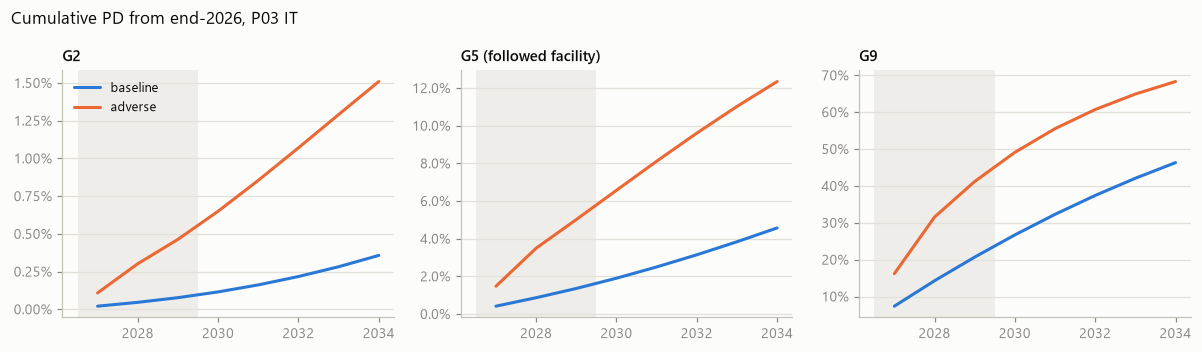

In [18]:
curves = run.table("pd_curves")
full = curves[curves["fraction"] == 1.0].sort_values(
    ["segment", "country", "scenario", "valuation_year", "cohort", "default_bucket"])
prior = full.groupby(["segment", "country", "scenario", "valuation_year", "cohort"])["s"].shift(1).fillna(1.0)
print(f"PD-03 on {len(full):,} buckets: "
      f"max |m - (S[k-1] - S)| = {(full['m'] - (prior - full['s'])).abs().max():.1e}, "
      f"max |F - (1 - S)| = {(full['f'] - (1 - full['s'])).abs().max():.1e}, "
      f"max |m - S[k-1] q| = {(full['m'] - prior * full['q']).abs().max():.1e}")

picked = nb.grade_order({grades[1], facility["current_grade"], grades[-2]}, grades)
mine = full[(full["segment"] == segment) & (full["country"] == country)
            & (full["valuation_year"] == start_year)]
fig, axes = plt.subplots(1, len(picked), figsize=(11, 3.2))
for ax, grade in zip(axes, picked):
    for s in scenarios:
        c = mine[(mine["cohort"] == grade) & (mine["scenario"] == s)]
        ax.plot(c["bucket_year"], c["f"], color=nb.SCENARIO_COLOURS[s], label=s)
    ax.axvspan(first - 0.5, years[-1] + 0.5, color=nb.GRID, alpha=0.5, linewidth=0)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(f"{grade}" + (" (followed facility)" if grade == facility["current_grade"] else ""),
                 loc="left")
axes[0].legend(loc="upper left")
fig.suptitle(f"Cumulative PD from end-{start_year}, {segment} {country}", x=0.01, ha="left")
fig.tight_layout()
plt.show()

### LGD

The exposure-weighted LGD per segment and year, then the formula checked on the followed facility.

In [19]:
lgd = run.report("lgd_by_z")
display(lgd.pivot_table(index="segment", columns=["scenario", "year"],
                        values="exposure_weighted_lgd").style.format("{:.2%}"))

w = ps["segments"][segment]["lgd_w"]
mine = run.table("lgd_of_year")
mine = mine[mine["facility_id"] == FACILITY].assign(
    formula=lambda d: norm.cdf(norm.ppf(facility["ttc_lgd"]) - w * d["z"]))
print(f"{FACILITY}: TTC LGD {facility['ttc_lgd']:.2%}, w = {w}; "
      f"largest |engine - formula|: {(mine['lgd'] - mine['formula']).abs().max():.1e}")
mine.set_index(["scenario", "year"])

F07007: TTC LGD 19.57%, w = 0.15; largest |engine - formula|: 0.0e+00


facility_id         z       lgd  ccf   formula
scenario year                                               
adverse  2027      F07007 -1.200000  0.249179  0.5  0.249179
         2028      F07007 -1.216667  0.249973  0.5  0.249973
         2029      F07007 -0.603333  0.221667  0.5  0.221667
baseline 2027      F07007  0.050000  0.193636  0.5  0.193636
         2028      F07007  0.136667  0.190087  0.5  0.190087
         2029      F07007  0.180000  0.188328  0.5  0.188328

### EAD and the ParameterRecords

The facility's records for the stressed scenario from the starting point: one row per default bucket. Prepayment shortens the loss profile through the not-prepaid share and never changes the stock. The checks run on every record.

In [20]:
params = run.table("parameters")
undrawn_ead = params["undrawn"] * params["ccf"].fillna(0.0)
print(f"{len(params):,} records; largest gaps: "
      f"drawn vs balance x not-prepaid {(params['ead_drawn'] - params['balance'] * params['not_prepaid_share']).abs().max():.1e}, "
      f"undrawn vs undrawn x CCF {(params['ead_undrawn'] - undrawn_ead).abs().max():.1e}, "
      f"total vs drawn + undrawn {(params['ead_total'] - params['ead_drawn'] - params['ead_undrawn']).abs().max():.1e}")
records = params[(params["facility_id"] == FACILITY) & (params["scenario"] == stressed)
                 & (params["valuation_year"] == start_year)]
records[["default_bucket", "bucket_year", "fraction", "z", "lgd", "prepayment_rate",
         "not_prepaid_share", "balance", "discount_factor", "undrawn", "ccf", "ead_drawn",
         "ead_undrawn", "ead_total"]]

767,638 records; largest gaps: drawn vs balance x not-prepaid 0.0e+00, undrawn vs undrawn x CCF 0.0e+00, total vs drawn + undrawn 3.7e-09


,default_bucket,bucket_year,fraction,z,lgd,prepayment_rate,not_prepaid_share,balance,discount_factor,undrawn,ccf,ead_drawn,ead_undrawn,ead_total
665976,1,2027,1.000000,-1.200000,0.249179,0.034012,1.000000,845025.91256,0.956412,1.318837e+06,0.5,845025.912560,659418.405126,1.504444e+06
665977,2,2028,1.000000,-1.216667,0.249973,0.033823,0.965988,845025.91256,0.914724,1.318837e+06,0.5,816285.262722,659418.405126,1.475704e+06
665978,3,2029,1.000000,-0.603333,0.221667,0.041339,0.933316,845025.91256,0.874854,1.318837e+06,0.5,788675.794468,659418.405126,1.448094e+06
665979,4,2030,1.000000,-0.472778,0.215887,0.043102,0.894733,845025.91256,0.836721,1.318837e+06,0.5,756072.651461,659418.405126,1.415491e+06
665980,5,2031,1.000000,-0.342222,0.210196,0.044925,0.856168,845025.91256,0.800250,1.318837e+06,0.5,723484.372778,659418.405126,1.382903e+06
665981,6,2032,0.416667,-0.211667,0.204594,0.046810,0.817705,845025.91256,0.785527,1.318837e+06,0.5,690981.664011,659418.405126,1.350400e+06


## R7 · Project the year

Each year R7 moves every facility's grade distribution one step: closing = opening × M(y). Whatever reaches D becomes a new S3 cohort, which keeps its entry year and origin stage. S3 never cures. Each grade slice takes its stage from the SICR rule against the facility's origination grade. Total GCA and undrawn stay at end-2026 levels (static balance sheet), and a facility that matures is replaced like for like.

In [21]:
slices = run.table("slices")
mix = slices.pivot_table(index=["scenario", "year"], columns="stage", values="gca",
                         aggfunc="sum").rename(columns=lambda s: f"S{s}")
mix["total"] = mix.sum(axis=1)
print("GCA by stage, EUR millions")
nb.millions(mix)

GCA by stage, EUR millions


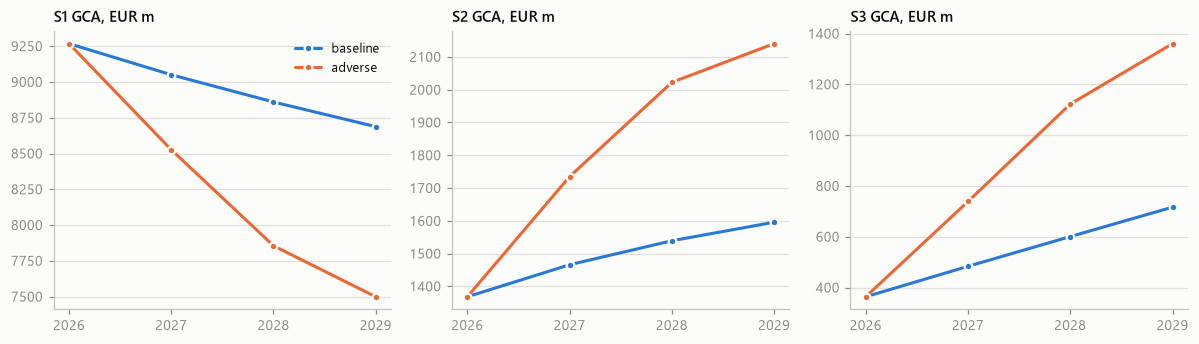

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, stage in zip(axes, ("S1", "S2", "S3")):
    for s in scenarios:
        line = mix.loc[s, stage] / nb.MILLION
        ax.plot(line.index, line.values, color=nb.SCENARIO_COLOURS[s], label=s, marker="o",
                markersize=5, markeredgecolor=nb.SURFACE, markeredgewidth=1.5)
    ax.set_title(f"{stage} GCA, EUR m", loc="left")
    ax.set_xticks(sorted(mix.index.get_level_values("year").unique()))
axes[0].legend(loc="best")
fig.tight_layout()
plt.show()

Stage flows in the first projected year, in EUR millions. Each flow is a sum of matrix cells applied to the slices, and the S3 row only flows to S3.

In [23]:
flows = run.table("stage_flows")
nb.millions(flows[flows["year"] == first].pivot_table(
    index=["scenario", "from_stage"], columns="to_stage", values="gca", aggfunc="sum", fill_value=0.0))

In [24]:
grade_flows = run.table("grade_flows")
g = grade_flows[(grade_flows["segment"] == segment) & (grade_flows["scenario"] == stressed)
                & (grade_flows["year"] == first)].pivot_table(
    index="from_grade", columns="to_grade", values="gca", aggfunc="sum")
g = g.reindex(index=nb.grade_order(g.index, grades), columns=nb.grade_order(g.columns, grades))
g = g[g.sum(axis=1) > 0]  # only the grades the book holds at the start of the year
print(f"Grade flows of {segment}, {stressed} {first}, all countries, EUR millions")
nb.millions(g, digits=2)

Grade flows of P03, adverse 2027, all countries, EUR millions


to_grade,G1,G2,G3,G4,G5,G6,G7,G8,G9,G10,D
from_grade,,,,,,,,,,,
G5,0.07,0.39,1.94,9.59,358.59,52.67,17.66,5.59,1.72,0.52,6.73
G6,0.01,0.06,0.27,1.27,6.26,234.40,34.28,11.37,3.57,1.09,9.88
G7,0.00,0.01,0.04,0.20,0.97,4.77,178.00,26.19,8.60,2.68,13.93
G8,0.00,0.00,0.01,0.04,0.19,0.89,4.35,161.16,25.05,8.20,20.14
G9,0.00,0.00,0.00,0.01,0.04,0.17,0.81,3.94,143.78,28.62,34.30


The S3 stock by cohort (EUR millions): the original S3 book, plus one cohort per entry year and origin stage. Then the static books, which must not move.

In [25]:
cohorts = run.report("s3_cohorts")
display(nb.millions(cohorts.pivot_table(index=["scenario", "cohort"], columns="year", values="gca",
                                        aggfunc="sum")))
books = run.report("static_books").groupby(["scenario", "year"])[
    ["gca", "undrawn", "converted", "gca_plus_converted"]].sum()
nb.millions(books)

## R8 · Year-end provisions

- **S1:** the 12-month ECL, Σ m[k] · EAD[k] · LGD[k] · DF[k] over the next bucket. At end-2029 it uses the interpolated 2030 loss rate.
- **S2:** the same sum over the remaining life.
- **Original S3:** max(GCA × LGD of the year, prior allowance), per exposure.
- **New S3 cohort:** booked once at flow × LGD of the default year, then floored.

Drawn amounts go to the on-balance allowance and undrawn amounts to the off-balance provision. Provisions by stage and method, on plus off, EUR millions:

In [26]:
prov = run.table("provisions")
prov = prov.assign(total=prov["allowance_on"] + prov["provision_off"])
nb.millions(prov.pivot_table(index=["stage", "method"], columns=["scenario", "year"], values="total",
                             aggfunc="sum"))

In [27]:
cover = run.report("impairment_by_stage").groupby(["scenario", "year", "stage"])[
    ["coverage_numerator", "coverage_denominator"]].sum()
cover = (cover["coverage_numerator"] / cover["coverage_denominator"]).unstack("stage")
print("Coverage (provisions / GCA) by stage")
display(cover.rename(columns=lambda s: f"S{s}").style.format("{:.2%}"))

s3 = prov[prov["stage"] == 3].groupby(["scenario", "year"]).agg(
    raw_on=("raw_on", "sum"), allowance_on=("allowance_on", "sum"),
    slices=("slice", "size"), floor_binding=("floor_binding", "sum"))
print("S3: raw against floored allowance (EUR millions), and how often the floor binds")
nb.millions(s3, ["raw_on", "allowance_on"])

Coverage (provisions / GCA) by stage


S3: raw against floored allowance (EUR millions), and how often the floor binds


In [28]:
buckets = run.table("ecl_buckets")
b = buckets[(buckets["segment"] == segment) & (buckets["stage"] == 2)
            & (buckets["valuation_year"] == first)].pivot_table(
    index="default_bucket", columns="scenario", values="ecl_on")
print(f"S2 lifetime ECL of {segment} at end-{first} by default bucket (first ten), EUR millions; "
      "R10 checks that the buckets sum to the provisions")
nb.millions(b.head(10), digits=2)

S2 lifetime ECL of P03 at end-2027 by default bucket (first ten), EUR millions; R10 checks that the buckets sum to the provisions


scenario,adverse,baseline
default_bucket,,
1,20.34,6.64
2,9.94,5.01
3,6.38,3.66
4,3.34,2.19
5,1.35,1.00
6,0.36,0.30
7,0.05,0.04


## R9 · Stock to flow

Charge(y) = closing − opening, separately for the on-balance allowance and the off-balance provision. The first opening is the frozen O4 allowance. FX movement is zero, and overlays are carried unchanged. EUR millions:

In [29]:
charges = run.table("charges")
cols = ["opening_on", "closing_on", "charge_on", "opening_off", "closing_off", "charge_off"]
bridge = charges.groupby(["scenario", "year"])[cols].sum()
bridge["charge_total"] = bridge["charge_on"] + bridge["charge_off"]
gap = max((charges["closing_on"] - charges["opening_on"] - charges["charge_on"]).abs().max(),
          (charges["closing_off"] - charges["opening_off"] - charges["charge_off"]).abs().max())
frozen = run.data("opening_provisions")[["allowance_on", "provision_off"]].sum().sum()
opening = charges[charges["year"] == first].groupby("scenario")[["opening_on", "opening_off"]].sum().sum(axis=1)
print(f"largest |closing - opening - charge| on one facility: {gap:.1e}")
print(f"first opening per scenario minus frozen O4 allowance: {(opening - frozen).abs().max():.1e}")
nb.millions(bridge)

largest |closing - opening - charge| on one facility: 0.0e+00
first opening per scenario minus frozen O4 allowance: 0.0e+00


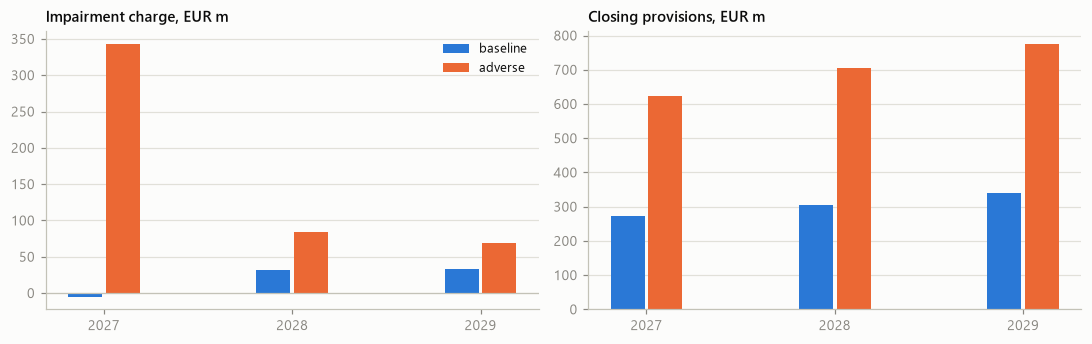

In [30]:
charge = bridge["charge_total"].unstack("scenario") / nb.MILLION
closing = (bridge["closing_on"] + bridge["closing_off"]).unstack("scenario") / nb.MILLION
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
width = 0.2
for i, s in enumerate(scenarios):
    offset = (i - (len(scenarios) - 1) / 2) * width
    axes[0].bar(charge.index + offset, charge[s], width=width * 0.9, color=nb.SCENARIO_COLOURS[s], label=s)
    axes[1].bar(closing.index + offset, closing[s], width=width * 0.9, color=nb.SCENARIO_COLOURS[s], label=s)
axes[0].axhline(0, color=nb.AXIS, linewidth=0.8)
axes[0].set_title("Impairment charge, EUR m", loc="left")
axes[1].set_title("Closing provisions, EUR m", loc="left")
for ax in axes:
    ax.set_xticks(years)
axes[0].legend(loc="upper right")
fig.tight_layout()
plt.show()

In [31]:
impairment = run.report("impairment")
cumulative = impairment[impairment["year"] == years[-1]].pivot_table(
    index="portfolio", columns="scenario", values="cumulative_charge")
opening_gca = book.groupby("portfolio")["gca"].sum()
opening_gca["Total"] = opening_gca.sum()
share = cumulative.div(opening_gca, axis=0)
print(f"Cumulative charge {first}-{years[-1]} by portfolio: EUR millions, then % of opening GCA")
display(nb.millions(cumulative))
share.style.format("{:.2%}")

Cumulative charge 2027-2029 by portfolio: EUR millions, then % of opening GCA


scenario,adverse,baseline
portfolio,,
P01,22.6,0.9
P02,8.0,3.0
P03,129.2,21.6
P04,150.0,9.5
P05,175.4,26.4
P06,10.9,-0.7
Total,496.0,60.6


scenario,adverse,baseline
portfolio,,
P01,1.89%,0.07%
P02,13.26%,4.98%
P03,8.61%,1.44%
P04,7.50%,0.48%
P05,4.38%,0.66%
P06,0.49%,-0.03%
Total,4.51%,0.55%


## Follow one facility through the years

The followed facility in the stressed scenario: its GCA per slice, the allowance per slice, and its charges. The facility starts in one grade. Each year the PiT matrix spreads it over grades, and the share that reaches D becomes a new S3 cohort named by its entry year and origin stage. Amounts in EUR.

In [32]:
mine = slices[(slices["facility_id"] == FACILITY) & (slices["scenario"] == stressed)]
order = nb.slice_order(mine["slice"], grades)
stage_of = mine.drop_duplicates("slice").set_index("slice")["stage"].reindex(order)
for value in ("gca", "allowance_on", "provision_off"):
    view = mine.pivot_table(index="slice", columns="year", values=value, aggfunc="sum").reindex(order)
    if not view.abs().to_numpy().any():
        continue
    view.insert(0, "stage", stage_of)
    print(f"{FACILITY} {stressed}: {value} by slice")
    display(view.style.format("{:,.0f}", subset=[c for c in view.columns if c != "stage"], na_rep=""))

F07007 adverse: gca by slice


year,stage,2026,2027,2028,2029
slice,,,,,
G1,1,,135,264,585
G2,1,,732,"1,336","2,562"
G3,1,,"3,591","6,190","10,556"
G4,1,,"17,785","28,784","43,224"
G5,1,"845,026","665,302","527,335","442,748"
G6,2,,"97,713","154,528","175,053"
G7,2,,"32,764","62,389","78,268"
G8,2,,"10,379","23,368","32,192"
G9,2,,"3,185","8,296","12,420"


F07007 adverse: allowance_on by slice


year,stage,2026,2027,2028,2029
slice,,,,,
G1,1,,0,0,0
G2,1,,0,0,0
G3,1,,2,2,3
G4,1,,28,21,28
G5,1,"1,107","2,385",925,695
G6,2,,"2,131","1,947","1,413"
G7,2,,"1,234","1,434","1,190"
G8,2,,600,861,799
G9,2,,295,527,560


F07007 adverse: provision_off by slice


year,stage,2026,2027,2028,2029
slice,,,,,
G1,1,,0,0,0
G2,1,,0,0,0
G3,1,,2,1,2
G4,1,,22,16,22
G5,1,864,"1,861",722,542
G6,2,,"1,755","1,598","1,139"
G7,2,,"1,014","1,175",958
G8,2,,492,705,644
G9,2,,241,430,450


In [33]:
charges[charges["facility_id"] == FACILITY].set_index(["scenario", "year"])[cols]

opening_on    closing_on    charge_on   opening_off   closing_off   charge_off
scenario year                                                                                  
adverse  2027   1107.153892   9917.463077  8810.309185    863.970729   7920.882805  7056.912076
         2028   9917.463077  13411.811376  3494.348299   7920.882805  10660.462455  2739.579649
         2029  13411.811376  15323.108137  1911.296761  10660.462455  12063.526124  1403.063670
baseline 2027   1107.153892   1918.409417   811.255525    863.970729   1550.972449   687.001720
         2028   1918.409417   2876.812799   958.403382   1550.972449   2301.217805   750.245356
         2029   2876.812799   3626.893357   750.080559   2301.217805   2864.975821   563.758016

## R10 · Reports

R10 sums money from the facility and bucket results, keeps the numerator and denominator of every ratio, checks the reconciliations against the §12.3 tolerances, and rounds only here. These are the files it wrote, and the summary:

In [34]:
reports_dir = run.path / "results" / "reports"
display(pd.DataFrame([{"report": p.name, "kB": round(p.stat().st_size / 1024, 1)}
                      for p in sorted(reports_dir.iterdir())]))
Markdown(run.summary())

,report,kB
0,driver_contributions.csv,46.7
1,ead_profile.csv,43.7
2,ecl_by_bucket.csv,32.8
3,grade_migration.csv,192.8
4,impairment.csv,4.9
5,impairment_by_stage.csv,14.6
6,lgd_by_z.csv,3.2
7,pd_curves.csv,3459.9
8,pit_matrices.csv,5723.8
9,portfolio_pd.csv,6.3


# Stress run summary · SYNTHETIC

Synthetic preparation run: not an EBA submission and not a bank forecast. Parameter set SYN-PS-0.1-proposed (PROPOSED); input set 514ed0e86e3dc760; variant core; code 0.1.0+03f04577c21e+dirty.5743ea01. Amounts in EUR millions, rounded here only.

## Headline

- baseline: cumulative charge 2027-2029 EUR 60.6m (first year -5.0m); closing provisions 2029 EUR 339.2m; S3 GCA 2029 EUR 716.5m
- adverse: cumulative charge 2027-2029 EUR 496.0m (first year 343.5m); closing provisions 2029 EUR 774.6m; S3 GCA 2029 EUR 1,360.4m

## Impairment (total book, EUR m)

| Scenario | Year | Opening | Charge | Closing | Cumulative charge |
|---|---:|---:|---:|---:|---:|
| adverse | 2027 | 278.6 | 343.5 | 622.1 | 343.5 |
| adverse | 2028 | 622.1 | 83.7 | 705.9 | 427.3 |
| adverse | 2029 | 705.9 | 68.8 | 774.6 | 496.0 |
| baseline | 2027 | 278.6 | -5.0 | 273.6 | -5.0 |
| baseline | 2028 | 273.6 | 32.0 | 305.6 | 26.9 |
| baseline | 2029 | 305.6 | 33.6 | 339.2 | 60.6 |

## Stage mix of GCA (EUR m)

| Scenario | Year | S1 | S2 | S3 | Total |
|---|---:|---:|---:|---:|---:|
| adverse | 2027 | 8,526.1 | 1,735.0 | 738.9 | 11,000.0 |
| adverse | 2028 | 7,855.4 | 2,022.4 | 1,122.2 | 11,000.0 |
| adverse | 2029 | 7,499.2 | 2,140.4 | 1,360.4 | 11,000.0 |
| baseline | 2027 | 9,050.1 | 1,466.2 | 483.6 | 11,000.0 |
| baseline | 2028 | 8,860.0 | 1,539.3 | 600.7 | 11,000.0 |
| baseline | 2029 | 8,687.7 | 1,595.9 | 716.5 | 11,000.0 |

## Static books per projected year (AT-44, EUR m)

| Scenario | Year | GCA | Undrawn | Converted | GCA + converted |
|---|---:|---:|---:|---:|---:|
| adverse | 2026 | 11,000.0 | 2,000.0 | 1,000.0 | 12,000.0 |
| adverse | 2027 | 11,000.0 | 2,000.0 | 1,000.0 | 12,000.0 |
| adverse | 2028 | 11,000.0 | 2,000.0 | 1,000.0 | 12,000.0 |
| adverse | 2029 | 11,000.0 | 2,000.0 | 1,000.0 | 12,000.0 |
| baseline | 2026 | 11,000.0 | 2,000.0 | 1,000.0 | 12,000.0 |
| baseline | 2027 | 11,000.0 | 2,000.0 | 1,000.0 | 12,000.0 |
| baseline | 2028 | 11,000.0 | 2,000.0 | 1,000.0 | 12,000.0 |
| baseline | 2029 | 11,000.0 | 2,000.0 | 1,000.0 | 12,000.0 |

## Starting point

- Facilities accepted: 10,000; rejected records: 0.
- Opening allowance (frozen, O4): EUR 278.6m.
- Currency EUR only; on-balance assets at amortised cost only.

Reports in this folder: starting_point_reconciliation.csv, stage_migration.csv, s3_cohorts.csv, grade_migration.csv, impairment.csv, impairment_by_stage.csv, static_books.csv and the parameter reports (z_scores.csv, pit_matrices.csv, pd_curves.csv, portfolio_pd.csv, lgd_by_z.csv, ead_profile.csv, ecl_by_bucket.csv).


## R11 · Seal the run

R11 writes `manifest.json` with the hash of every input and output and makes the folder read-only. A rerun from the manifest (`uv run stress rerun --run runs/<run_id>`) must give identical output hashes. The table after the outputs compares this run with every other sealed run of the same input set, scenarios and variant: runs on the same code version must be identical. Only a committed code version names the code exactly; a `+dirty` version means the engine had uncommitted changes when it ran.

In [35]:
print(f"{len(run.manifest['outputs'])} outputs hashed; digest {run.manifest['outputs_digest']}")
display(run.outputs())
nb.reproduction(run)

34 outputs hashed; digest d945f6a1ac88ef0e025855eeba6a58ed57a322cfa857db9b77639c05d771bd58


,file,kB,sha256,rows,columns
0,results/cf_schedule.parquet,3352.5,250ccdffaf3fc9f7,383819.0,15.0
1,results/charges.parquet,1967.8,302e597ff80a49cd,60000.0,13.0
2,results/driver_contributions.parquet,7.3,41543ce29db3a909,648.0,10.0
3,results/drivers.parquet,5.5,42dbb3c8fa8729bf,2856.0,7.0
4,results/ecl_buckets.parquet,12.8,43b3398d48456511,708.0,7.0
5,results/grade_flows.parquet,220.2,8646d9868bd45932,27720.0,7.0
6,results/indices.parquet,4.1,e6a47b50c09512bc,72.0,6.0
7,results/lgd_of_year.parquet,705.3,32bc49f76b546378,60000.0,6.0
8,results/parameters.parquet,15737.7,9a4905401a578931,767638.0,23.0
9,results/pd_curves.parquet,3654.8,9280a551f814d5b8,252720.0,14.0


,run_id,status,code_version,same_code_version,outputs_differing,identical
0,20261017T2155Z-core-0cfeb241,SYNTHETIC,0.1.0+03f04577c21e+dirty.920ce967,False,10,False
1,20261017T2155Z-core-0cfeb241-2,SYNTHETIC,0.1.0+03f04577c21e+dirty.920ce967,False,10,False
2,20261017T2225Z-core-0cfeb241,SYNTHETIC,0.1.0+03f04577c21e+dirty.920ce967,False,2,False
3,20261017T2232Z-core-0cfeb241,SYNTHETIC,0.1.0+03f04577c21e+dirty.920ce967,False,2,False
4,20261017T2301Z-core-b559d9dd,SYNTHETIC,0.1.0+03f04577c21e+dirty.5743ea01,True,0,True
